Mounted at /content/drive


In [ ]:
!pip install -q osmnx geopandas rasterio rasterstats pyyaml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 3.8 MB/s eta 0:00:00


In [ ]:
# Split the boundary into its separate parts and keep the largest (main city)
parts = city.explode(index_parts=False).reset_index(drop=True)
parts["area_km2"] = parts.area / 1e6
print(parts[["area_km2"]])
city = parts.loc[[parts["area_km2"].idxmax()]].reset_index(drop=True)

pts = city.sample_points(500, rng=42).explode(index_parts=False)
homes = gpd.GeoDataFrame(
    {"home_id": [f"H{i:04d}" for i in range(1, len(pts) + 1)]},
    geometry=pts.values,
    crs=city.crs,
)
print("Number of homes:", len(homes))

     area_km2
0  318.357897
Number of homes: 500


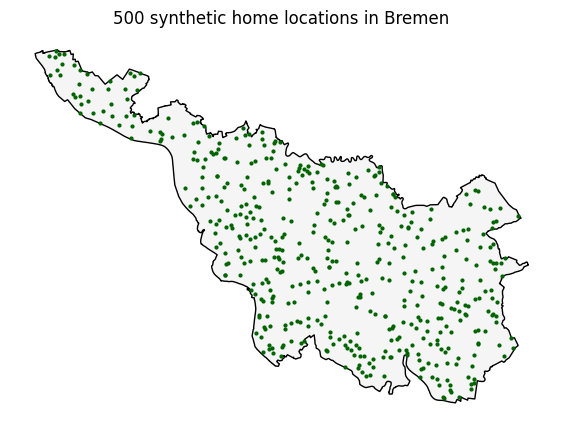

In [ ]:
ax = city.plot(edgecolor="black", facecolor="whitesmoke", figsize=(7, 7))
homes.plot(ax=ax, markersize=4, color="darkgreen")
ax.set_title("500 synthetic home locations in Bremen")
ax.set_axis_off()

In [ ]:
import os, shutil

base = "/content/drive/MyDrive/env-exposure-linkage"
os.makedirs(f"{base}/data/processed", exist_ok=True)

# Save locally first, then copy to Drive (avoids the Drive/GeoPackage problem)
homes.to_file("/content/homes.gpkg", driver="GPKG")
city.to_file("/content/bremen_boundary.gpkg", driver="GPKG")

shutil.copy("/content/homes.gpkg", f"{base}/data/processed/homes.gpkg")
shutil.copy("/content/bremen_boundary.gpkg", f"{base}/data/processed/bremen_boundary.gpkg")

os.chdir(base)
print("Saved! Files in data/processed:", os.listdir(f"{base}/data/processed"))

Saved! Files in data/processed: ['homes.gpkg', 'bremen_boundary.gpkg']


In [ ]:
from shapely.geometry import box

# Simple rectangle around Bremen (in lat/lon), much smaller request
minx, miny, maxx, maxy = city.to_crs(4326).total_bounds
bremen_box = box(minx, miny, maxx, maxy)

green = ox.features_from_polygon(bremen_box, green_tags)
blue = ox.features_from_polygon(bremen_box, blue_tags)

# Keep only areas or lines, convert to metres
green = green[green.geom_type.isin(["Polygon", "MultiPolygon"])].to_crs(25832)
blue = blue[blue.geom_type.isin(["Polygon", "MultiPolygon", "LineString", "MultiLineString"])].to_crs(25832)

# Cut to the Bremen boundary
green = gpd.clip(green, city)
blue = gpd.clip(blue, city)

print("Green spaces:", len(green))
print("Blue spaces:", len(blue))

Green spaces: 9541
Blue spaces: 2467


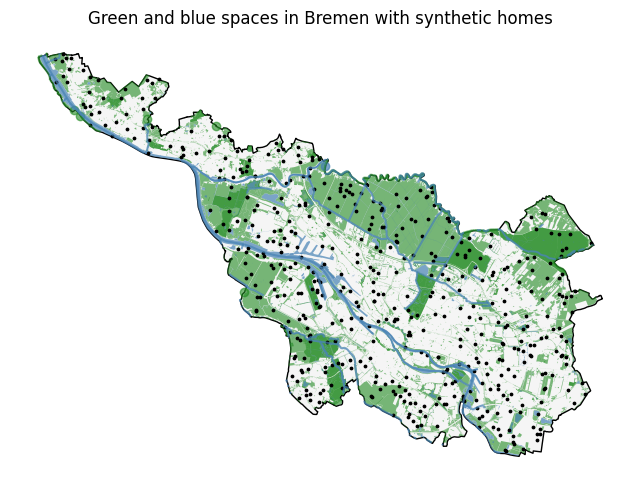

In [ ]:
ax = city.plot(facecolor="whitesmoke", edgecolor="black", figsize=(8, 8))
green.plot(ax=ax, color="forestgreen", alpha=0.6)
blue.plot(ax=ax, color="steelblue", alpha=0.7)
homes.plot(ax=ax, color="black", markersize=3)
ax.set_title("Green and blue spaces in Bremen with synthetic homes")
ax.set_axis_off()

In [ ]:
# Many green areas overlap (e.g. grass inside a park). Merge them so area isn't counted twice.
green["geometry"] = green.geometry.make_valid()
blue["geometry"] = blue.geometry.make_valid()

green_union = green.union_all()
blue_union = blue.union_all()
print("Merged.")

Merged.


In [ ]:
# --- Setup and reload (run this first whenever Colab restarts) ---
from google.colab import drive
drive.mount('/content/drive')

!pip install -q osmnx geopandas rasterio rasterstats pyyaml

import os, shutil
import geopandas as gpd
import osmnx as ox

base = "/content/drive/MyDrive/env-exposure-linkage"
os.chdir(base)

# Copy saved files to Colab's disk, then read them (avoids the Drive/GeoPackage issue)
files = {
    "homes": "data/processed/homes.gpkg",
    "city": "data/processed/bremen_boundary.gpkg",
    "green": "data/raw/osm_green.gpkg",
    "blue": "data/raw/osm_blue.gpkg",
}
data = {}
for name, path in files.items():
    shutil.copy(f"{base}/{path}", f"/content/{name}.gpkg")
    data[name] = gpd.read_file(f"/content/{name}.gpkg")

homes, city, green, blue = data["homes"], data["city"], data["green"], data["blue"]
print("Loaded:", len(homes), "homes,", len(green), "green,", len(blue), "blue")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: 500 homes, 9541 green, 2467 blue


In [ ]:
green["geometry"] = green.geometry.make_valid()
blue["geometry"] = blue.geometry.make_valid()

green_union = green.union_all()
blue_union = blue.union_all()
print("Merged.")

Merged.


In [ ]:

# --- Cell B: Share of green space within 100, 300 and 500 m ---

# 1. Split the merged green area into separate pieces
green_parts = gpd.GeoDataFrame(geometry=[green_union], crs=homes.crs).explode(index_parts=False)

# 2. Keep areas only (remove stray lines and points from geometry repair)
green_parts = green_parts[green_parts.geom_type.isin(["Polygon", "MultiPolygon"])]

# 3. Simplify by 1 m to speed things up, then drop empty or invalid shapes
green_parts["geometry"] = green_parts.geometry.simplify(1)
green_parts = green_parts[~green_parts.is_empty & green_parts.is_valid].reset_index(drop=True)
print("Green pieces:", len(green_parts))

# 4. For each buffer size, measure the share of the circle that is green
for b in [100, 300, 500]:
    buffers = gpd.GeoDataFrame(
        {"home_id": homes["home_id"]},
        geometry=homes.buffer(b),
        crs=homes.crs,
    )

    overlap = gpd.overlay(buffers, green_parts, how="intersection")
    green_area = overlap.assign(a=overlap.area).groupby("home_id")["a"].sum()

    homes[f"green_share_{b}m"] = (
        homes["home_id"].map(green_area).fillna(0) / buffers.area.values
    ).round(3)
    print(f"{b} m done")

homes[["home_id", "green_share_100m", "green_share_300m", "green_share_500m"]].head()

Green pieces: 5250
100 m done
300 m done
500 m done


,home_id,green_share_100m,green_share_300m,green_share_500m
0,H0001,0.000,0.130,0.265
1,H0002,0.902,0.623,0.576
2,H0003,1.000,0.960,0.931
3,H0004,0.504,0.357,0.339
4,H0005,0.109,0.309,0.245


In [ ]:
homes["dist_green_m"] = homes.distance(green_union).round(1)
homes["dist_blue_m"] = homes.distance(blue_union).round(1)

homes[["green_share_100m", "green_share_300m", "green_share_500m",
       "dist_green_m", "dist_blue_m"]].describe().round(2)

,green_share_100m,green_share_300m,green_share_500m,dist_green_m,dist_blue_m
count,500.00,500.00,500.00,500.00,500.00
mean,0.41,0.40,0.39,48.33,226.74
std,0.39,0.33,0.31,73.53,211.09
min,0.00,0.00,0.00,0.00,0.00
25%,0.03,0.12,0.14,0.00,61.30
50%,0.27,0.31,0.30,12.25,170.45
75%,0.86,0.66,0.60,74.15,342.78
max,1.00,1.00,1.00,522.10,1052.30


Saved dataset and map.


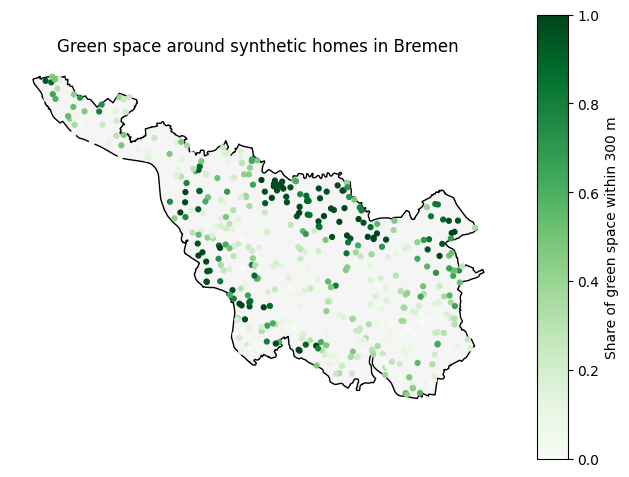

In [ ]:
import matplotlib.pyplot as plt

os.makedirs(f"{base}/outputs", exist_ok=True)

# Linked exposure dataset (CSV is easy for anyone to open)
homes.drop(columns="geometry").to_csv(f"{base}/data/processed/homes_exposures.csv", index=False)

# Map as an image for the README
ax = city.plot(facecolor="whitesmoke", edgecolor="black", figsize=(8, 8))
homes.plot(ax=ax, column="green_share_300m", cmap="Greens", markersize=12, legend=True,
           legend_kwds={"label": "Share of green space within 300 m"})
ax.set_title("Green space around synthetic homes in Bremen")
ax.set_axis_off()
plt.savefig(f"{base}/outputs/map_green_share_300m.png", dpi=200, bbox_inches="tight")

print("Saved dataset and map.")

Residential area (km²): 73.6 | type: MultiPolygon
Number of homes: 500


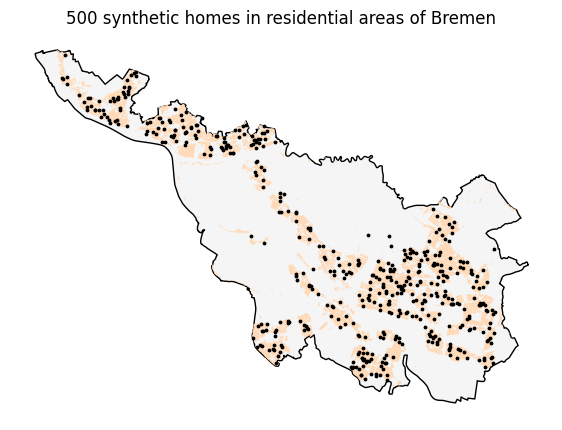

In [ ]:
from shapely.geometry import box
from shapely.ops import unary_union
import matplotlib.pyplot as plt

# Download residential areas
minx, miny, maxx, maxy = city.to_crs(4326).total_bounds
resid = ox.features_from_polygon(box(minx, miny, maxx, maxy), {"landuse": ["residential"]})
resid = resid[resid.geom_type.isin(["Polygon", "MultiPolygon"])].to_crs(25832)
resid["geometry"] = resid.geometry.make_valid()
resid = gpd.clip(resid, city)

# Keep areas only (clipping and repair can create stray lines/points)
resid = resid.explode(index_parts=False)
resid = resid[resid.geom_type == "Polygon"]
resid = resid[~resid.is_empty]
resid_area = unary_union(resid.geometry.values)
print("Residential area (km²):", round(resid_area.area / 1e6, 1), "| type:", resid_area.geom_type)

# Sample 500 homes inside residential areas
resid_gdf = gpd.GeoDataFrame(geometry=[resid_area], crs=city.crs)
pts = resid_gdf.sample_points(500, rng=42).explode(index_parts=False)
homes = gpd.GeoDataFrame(
    {"home_id": [f"H{i:04d}" for i in range(1, len(pts) + 1)]},
    geometry=pts.values, crs=city.crs,
)
print("Number of homes:", len(homes))

# Save
homes.to_file("/content/homes.gpkg", driver="GPKG")
shutil.copy("/content/homes.gpkg", f"{base}/data/processed/homes.gpkg")
resid_gdf.to_file("/content/residential.gpkg", driver="GPKG")
shutil.copy("/content/residential.gpkg", f"{base}/data/raw/osm_residential.gpkg")

# Check map
ax = city.plot(facecolor="whitesmoke", edgecolor="black", figsize=(7, 7))
resid_gdf.plot(ax=ax, color="peachpuff")
homes.plot(ax=ax, color="black", markersize=3)
ax.set_title("500 synthetic homes in residential areas of Bremen")
ax.set_axis_off()
plt.show()

In [ ]:
# Make sure the merged green and blue areas exist (from Cell A)
if "green_union" not in globals():
    green["geometry"] = green.geometry.make_valid()
    blue["geometry"] = blue.geometry.make_valid()
    green_union = green.union_all()
    blue_union = blue.union_all()

# Split merged green area into clean, separate polygons
green_parts = gpd.GeoDataFrame(geometry=[green_union], crs=homes.crs).explode(index_parts=False)
green_parts = green_parts[green_parts.geom_type.isin(["Polygon", "MultiPolygon"])]
green_parts["geometry"] = green_parts.geometry.simplify(1)
green_parts = green_parts[~green_parts.is_empty & green_parts.is_valid].reset_index(drop=True)
print("Green pieces:", len(green_parts))

for b in [100, 300, 500]:
    buffers = gpd.GeoDataFrame(
        {"home_id": homes["home_id"]},
        geometry=homes.buffer(b),
        crs=homes.crs,
    )
    overlap = gpd.overlay(buffers, green_parts, how="intersection")
    green_area = overlap.assign(a=overlap.area).groupby("home_id")["a"].sum()
    homes[f"green_share_{b}m"] = (
        homes["home_id"].map(green_area).fillna(0) / buffers.area.values
    ).round(3)
    print(f"{b} m done")

homes[["home_id", "green_share_100m", "green_share_300m", "green_share_500m"]].head()

Green pieces: 5250
100 m done
300 m done
500 m done


,home_id,green_share_100m,green_share_300m,green_share_500m
0,H0001,0.059,0.151,0.161
1,H0002,0.045,0.053,0.115
2,H0003,0.000,0.033,0.025
3,H0004,0.000,0.024,0.046
4,H0005,0.039,0.084,0.105


In [ ]:
homes["dist_green_m"] = homes.distance(green_union).round(1)
homes["dist_blue_m"] = homes.distance(blue_union).round(1)

homes[["green_share_100m", "green_share_300m", "green_share_500m",
       "dist_green_m", "dist_blue_m"]].describe().round(2)

,green_share_100m,green_share_300m,green_share_500m,dist_green_m,dist_blue_m
count,500.00,500.00,500.00,500.00,500.00
mean,0.08,0.13,0.15,86.77,359.03
std,0.12,0.11,0.11,69.92,233.60
min,0.00,0.00,0.01,0.00,1.00
25%,0.00,0.04,0.08,33.90,183.90
50%,0.03,0.09,0.12,68.35,310.35
75%,0.11,0.17,0.20,120.65,501.20
max,0.67,0.66,0.64,348.70,1208.30


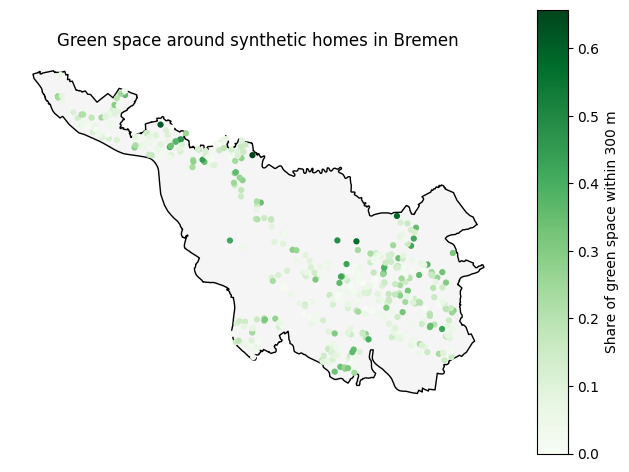

Saved dataset and map.


In [ ]:
os.makedirs(f"{base}/outputs", exist_ok=True)

# Save the linked exposure dataset
homes.drop(columns="geometry").to_csv(f"{base}/data/processed/homes_exposures.csv", index=False)
homes.to_file("/content/homes_exposures.gpkg", driver="GPKG")
shutil.copy("/content/homes_exposures.gpkg", f"{base}/data/processed/homes_exposures.gpkg")

# Map
ax = city.plot(facecolor="whitesmoke", edgecolor="black", figsize=(8, 8))
homes.plot(ax=ax, column="green_share_300m", cmap="Greens", markersize=12, legend=True,
           legend_kwds={"label": "Share of green space within 300 m"})
ax.set_title("Green space around synthetic homes in Bremen")
ax.set_axis_off()
plt.savefig(f"{base}/outputs/map_green_share_300m.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved dataset and map.")